In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#Data load and plot

In [8]:
df = sns.load_dataset("tips")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
df.shape

(244, 7)

In [9]:
X = df["total_bill"].values
y = df["tip"].values
print(X)
print(y)

[16.99 10.34 21.01 23.68 24.59 25.29  8.77 26.88 15.04 14.78 10.27 35.26
 15.42 18.43 14.83 21.58 10.33 16.29 16.97 20.65 17.92 20.29 15.77 39.42
 19.82 17.81 13.37 12.69 21.7  19.65  9.55 18.35 15.06 20.69 17.78 24.06
 16.31 16.93 18.69 31.27 16.04 17.46 13.94  9.68 30.4  18.29 22.23 32.4
 28.55 18.04 12.54 10.29 34.81  9.94 25.56 19.49 38.01 26.41 11.24 48.27
 20.29 13.81 11.02 18.29 17.59 20.08 16.45  3.07 20.23 15.01 12.02 17.07
 26.86 25.28 14.73 10.51 17.92 27.2  22.76 17.29 19.44 16.66 10.07 32.68
 15.98 34.83 13.03 18.28 24.71 21.16 28.97 22.49  5.75 16.32 22.75 40.17
 27.28 12.03 21.01 12.46 11.35 15.38 44.3  22.42 20.92 15.36 20.49 25.21
 18.24 14.31 14.    7.25 38.07 23.95 25.71 17.31 29.93 10.65 12.43 24.08
 11.69 13.42 14.26 15.95 12.48 29.8   8.52 14.52 11.38 22.82 19.08 20.27
 11.17 12.26 18.26  8.51 10.33 14.15 16.   13.16 17.47 34.3  41.19 27.05
 16.43  8.35 18.64 11.87  9.78  7.51 14.07 13.13 17.26 24.55 19.77 29.85
 48.17 25.   13.39 16.49 21.5  12.66 16.21 13.81 17.

In [6]:
print(X.shape,y.shape)

(244,) (244,)


Text(0, 0.5, 'Tip')

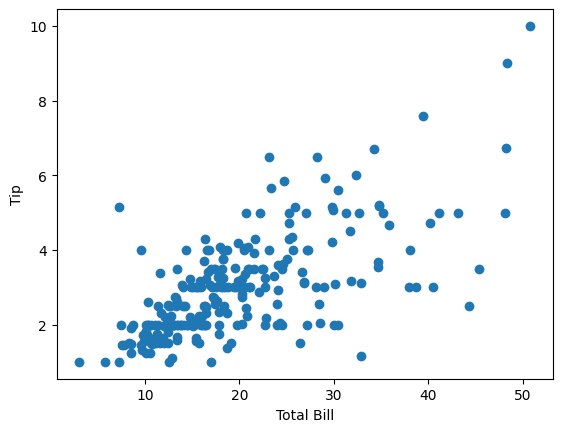

In [7]:
plt.scatter(X,y)
plt.xlabel("Total Bill")
plt.ylabel("Tip")



In [16]:
#cost function
def compute_cost(X,y,w,b):
    cost = []
    m = X.shape[0]
    for i in range(m):
        f_wb = w * X[i] + b
        diff= (f_wb - y[i]) ** 2
        cost.append(diff)
    total_cost = (1/(2*m)) * np.sum(cost)
    return total_cost



In [9]:
#cost computation for different values of w and b
print(compute_cost(X, y, 0, 0))
print(compute_cost(X, y, 0.1, 0))

5.448141803278689
1.0388841864754097


In [17]:
#gradient computation function
def compute_gradient(X,y,w,b):
    m = X.shape[0]
    dj_dw = 0
    dj_db = 0
    for i in range(m):
        f_wb = w * X[i] + b
        diff = f_wb - y[i]
        dj_dw = dj_dw + (diff * X[i])
        dj_db = dj_db + diff
    dj_dw = dj_dw/m
    dj_db = dj_db/m
    return dj_dw, dj_db


In [11]:
print(compute_gradient(X,y,0,0))

(np.float64(-67.61315901639345), np.float64(-2.9982786885245902))


In [12]:
print(-np.mean(X * y), -np.mean(y))

-67.61315901639344 -2.99827868852459


In [19]:
#gradient computation function with vectorization
def compute_gradient_vectorized(X,y,w,b):
    f_wb = w * X + b
    diff = f_wb - y
    dj_dw  = (np.sum(diff * X))/X.shape[0]
    dj_db = (np.sum(diff))/X.shape[0]
    return dj_dw, dj_db

In [14]:
print(compute_gradient_vectorized(X,y,0,0))
print(-np.mean(X*y), -np.mean(y))

(np.float64(-67.61315901639344), np.float64(-2.99827868852459))
-67.61315901639344 -2.99827868852459


In [15]:
a = compute_gradient(X, y, 0.1, 0.5)
b_ = compute_gradient_vectorized(X, y, 0.1, 0.5)
print(np.isclose(a[0], b_[0]), np.isclose(a[1], b_[1]))

True True


In [20]:
#gradient descent function
def gradient_descent(X,y,w_in,b_in,alpha,num_iters):
    w = w_in
    b = b_in
    J_history = []
    for i in range(num_iters):
        dj_dw = compute_gradient_vectorized(X,y,w,b)[0]
        dj_db = compute_gradient_vectorized(X,y,w,b)[1]
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        if i < 100000:
            J_history.append(compute_cost(X,y,w,b))
    return w,b,J_history

In [17]:
w, b, costs = gradient_descent(X, y, 0, 0, 0.001, 10000)
print(w, b)
print(costs[0], costs[-1])

0.11222951993556561 0.7490313513333304
1.946881100304734 0.5204696674248992


In [21]:
#taking larger number of iterations
w, b, costs = gradient_descent(X, y, 0, 0, 0.001, 100000)
print(w, b)
print(costs[0], costs[-1])

0.10502451942860035 0.9202695649699164
1.946881100304734 0.5180097210056888


In [19]:
#taking a larger learning rate
w, b, costs = gradient_descent(X, y, 0, 0, 0.01, 10000)
print(w, b)
print(costs[0], costs[-1])

/Users/swatiagarwal/Library/Python/3.9/lib/python/site-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/var/folders/1g/2f61jcl17nsglr8096_rgy1h0000gn/T/ipykernel_1884/3719040731.py:7: RuntimeWarning: overflow encountered in scalar power
  diff= (f_wb - y[i]) ** 2
/var/folders/1g/2f61jcl17nsglr8096_rgy1h0000gn/T/ipykernel_1884/3502444048.py:9: RuntimeWarning: invalid value encountered in scalar subtract
  w = w - alpha * dj_dw


nan nan
67.56967676019816 nan


Text(0, 0.5, 'Cost')

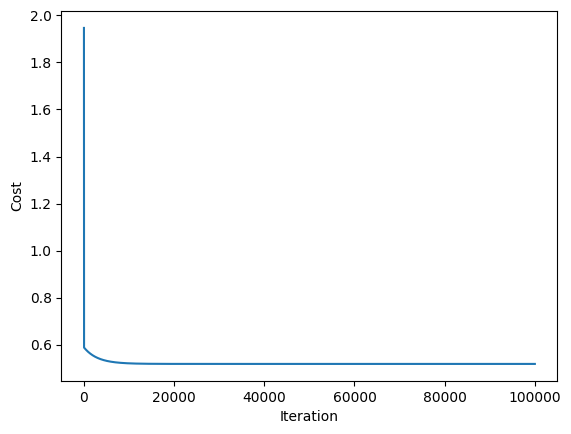

In [25]:
plt.plot(costs)
plt.xlabel("Iteration")
plt.ylabel("Cost")

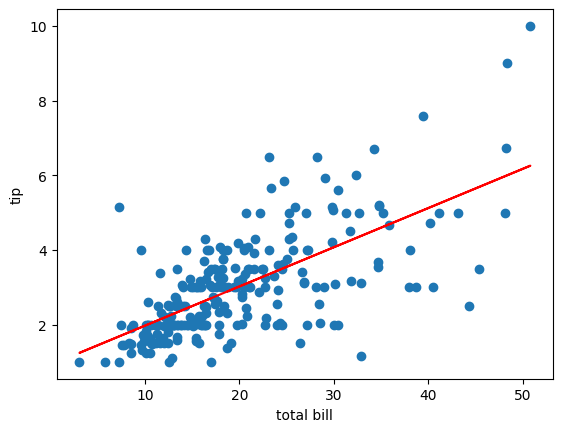

In [31]:
plt.scatter(X,y)
plt.plot(X, w*X + b, color = "red")
plt.xlabel("total bill")
plt.ylabel("tip")
plt.show()

In [22]:
#checking with sklearn
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X.reshape(-1,1), y)
print(model.coef_)
print(model.intercept_)
print(w,b)

[0.10502452]
0.920269613554674
0.10502451942860035 0.9202695649699164


#Feature Scaling

In [23]:
X_scaled = (X - X.mean()) / X.std()

print(X.mean(), X.std())
print(X_scaled.mean(), X_scaled.std())
print(X[:5])
print(X_scaled[:5])

19.78594262295082 8.884150577771132
-7.871663248366888e-17 1.0
[16.99 10.34 21.01 23.68 24.59]
[-0.31471131 -1.06323531  0.1377799   0.4383151   0.5407447 ]


In [24]:
w_s, b_s, costs_s = gradient_descent(X_scaled, y, 0, 0, 0.01, 1000)
print(w_s, b_s)
print(costs_s[0], costs_s[-1])

0.9330133457113675 2.9981492490935224
5.350032174841456 0.5180097301942549


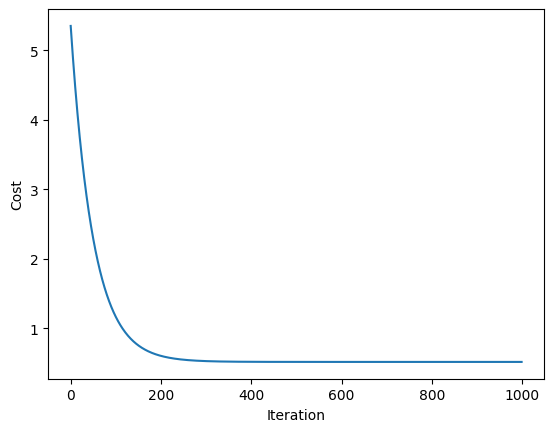

In [25]:
plt.plot(costs_s)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.show()

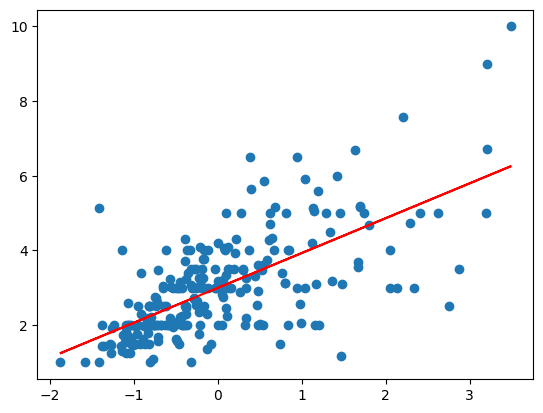

In [28]:
plt.scatter(X_scaled,y)
plt.plot(X_scaled, w_s* X_scaled + b_s, color = "red")
plt.show()

In [29]:
#finding out original w and b from scaled w and b
w_orig = w_s / X.std()
b_orig = b_s - w_s * X.mean() / X.std()
print(w_orig, b_orig)
print(model.coef_[0], model.intercept_)

0.10501998334492921 0.9202298843675023
0.10502451738435332 0.920269613554674


In [ ]:
#finding out orginal w and b from scaled w and b and increasing the number of iterations
w_s2, b_s2, costs_s2 = gradient_descent(X_scaled, y, 0, 0, 0.01, 5000)
w_orig2 = w_s2 / X.std()
b_orig2 = b_s2 - w_s2 * X.mean() / X.std()
print(w_orig2, b_orig2)
print(model.coef_[0], model.intercept_)

0.10502451738435277 0.9202696135546633
0.10502451738435332 0.920269613554674
